# Search Exercise 4 – Evolutionary algorithm with unknown pattern length

**Task.** The secret pattern can now have any length between 2 and 32 bits. The length is unknown to the algorithm. We change the evaluation, mutation and crossover so they work with variable lengths, and compare **mutation only**, **crossover only** and **mutation and crossover**, each with 30 tests.

**Key idea.** The algorithm never sees the secret length. It only sees the **feedback score** of a guess, the same way the player sees feedback in Mastermind.

## Step 0 – Set-up

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)            # global seed for reproducibility
MIN_LEN, MAX_LEN = 2, 32     # allowed range of the secret pattern length
SEEDS = list(range(30))      # 30 fixed seeds -> 30 tests per result

## Step 1 – The feedback (oracle)

The secret pattern is hidden inside an **oracle**. The algorithm can only call `oracle.score(guess)` and gets one number back.

**Scoring rule (our assumption):**
- Compare the guess with the secret pattern position by position, up to the shorter of the two lengths. Each matching bit gives +1.
- Each **unmatched length** position counts as wrong: subtract 1 for every bit by which the guess is longer or shorter than the secret pattern.

So the score is:
$$\text{score}(g) = \#\{i < \min(|g|, L) : g_i = t_i\} - |\,|g| - L\,|$$

The maximum score is $$L$$, reached only when the guess has the right length and matches every bit. The algorithm does not know $$L$$, but it can compare scores.

The oracle also tells us whether the guess is solved. This flag is used only to measure success, not by the algorithm.

In [2]:
class Oracle:
    """Hidden secret pattern. The algorithm only sees score(); solved() is used for the evaluation."""
    def __init__(self, secret):
        self.secret = np.asarray(secret)
        self.calls = 0

    def score(self, guess):
        self.calls += 1
        L, m = len(self.secret), min(len(guess), len(self.secret))
        matches = int(np.sum(guess[:m] == self.secret[:m]))
        return matches - abs(len(guess) - L)

    def solved(self, guess):
        return len(guess) == len(self.secret) and np.array_equal(guess, self.secret)

# Quick checks
secret = np.array([1, 0, 1, 1])
o = Oracle(secret)
assert o.score(secret) == 4                           # exact guess -> maximum = L
assert o.score(np.array([1, 0, 1, 1, 0])) == 3        # one extra bit -> penalty 1
assert o.score(np.array([1, 0])) == 0                 # two bits missing -> 2 matches - 2 penalty
assert o.solved(secret) and not o.solved(np.array([1, 0, 1]))
print("Oracle checks passed.")

Oracle checks passed.


## Step 2 – Random patterns of unknown length

A random guess gets a random length between 2 and 32. This means the starting population contains many different lengths.

In [3]:
def random_pattern(rng):
    length = rng.integers(MIN_LEN, MAX_LEN + 1)     # 2 .. 32 inclusive
    return rng.integers(0, 2, size=length)

def fix_length(bits, rng):
    """Keep every pattern inside [MIN_LEN, MAX_LEN]."""
    bits = np.asarray(bits)
    if len(bits) > MAX_LEN:
        bits = bits[:MAX_LEN]
    while len(bits) < MIN_LEN:
        bits = np.append(bits, rng.integers(0, 2))
    return bits

rng_t = np.random.default_rng(0)
lengths = [len(random_pattern(rng_t)) for _ in range(1000)]
assert min(lengths) >= MIN_LEN and max(lengths) <= MAX_LEN
print("Random lengths between", min(lengths), "and", max(lengths))

Random lengths between 2 and 32


## Step 3 – Mutation and crossover for variable lengths

- **`mutate`** chooses one of three changes:
  - flip one bit (50 %),
  - insert a random bit at a random position (25 %), if the pattern is shorter than 32,
  - delete one bit (25 %), if the pattern is longer than 2.
- **`crossover`** is one-point crossover between two parents of different lengths. The child takes a prefix from parent A and a suffix from parent B. The cut points are chosen independently, so the child length can differ from both parents. The length is then fixed to the allowed range.

In [4]:
def mutate(guess, rng):
    child = guess.copy()
    r = rng.random()
    if r < 0.5 or (len(child) <= MIN_LEN and r >= 0.75):
        i = rng.integers(len(child))
        child[i] ^= 1                                   # flip one bit
    elif r < 0.75 and len(child) < MAX_LEN:
        i = rng.integers(len(child) + 1)
        child = np.insert(child, i, rng.integers(0, 2)) # insert a bit
    elif len(child) > MIN_LEN:
        i = rng.integers(len(child))
        child = np.delete(child, i)                     # delete a bit
    return fix_length(child, rng)

def crossover(parent_a, parent_b, rng):
    ca = rng.integers(0, len(parent_a) + 1)
    cb = rng.integers(0, len(parent_b) + 1)
    child = np.concatenate([parent_a[:ca], parent_b[cb:]])
    return fix_length(child, rng)

# Quick checks
rng_c = np.random.default_rng(5)
for _ in range(500):
    p1, p2 = random_pattern(rng_c), random_pattern(rng_c)
    c = crossover(p1, p2, rng_c)
    m = mutate(c, rng_c)
    assert MIN_LEN <= len(c) <= MAX_LEN and MIN_LEN <= len(m) <= MAX_LEN
    assert set(np.unique(m)) <= {0, 1}
print("Operator checks passed (500 random cases).")

Operator checks passed (500 random cases).


## Step 4 – Evolutionary loop with the oracle

The loop is the same as in Exercise 3, with two changes:
- the fitness is the oracle score (the algorithm does not see the secret pattern),
- the stop condition uses the **oracle's solved flag** only to detect success. The algorithm itself stops only when the best score has not improved for 20 generations (stagnation), or after 500 generations.

In [5]:
def run_ga(oracle, method, rng, pop_size=100, elite_frac=0.3, stagnation=20, max_gen=500):
    n_elite = int(elite_frac * pop_size)
    population = [random_pattern(rng) for _ in range(pop_size)]
    best, best_guess, stale, gen = -10**9, None, 0, 0
    solved_flag = False

    while True:
        scores = np.array([oracle.score(g) for g in population])
        order = np.argsort(-scores, kind="stable")
        elite = [population[i] for i in order[:n_elite]]

        gen += 1
        if scores[order[0]] > best:
            best, best_guess, stale = int(scores[order[0]]), elite[0], 0
        else:
            stale += 1
        if oracle.solved(best_guess):
            solved_flag = True
            break
        if stale >= stagnation or gen >= max_gen:
            break

        children = []
        while len(children) < pop_size - n_elite:
            if method == "mutation":
                child = mutate(elite[rng.integers(n_elite)], rng)
            elif method == "crossover":
                a, b = rng.choice(n_elite, 2, replace=False)
                child = crossover(elite[a], elite[b], rng)
            elif method == "both":
                a, b = rng.choice(n_elite, 2, replace=False)
                child = crossover(elite[a], elite[b], rng)
                if rng.random() < 0.5:
                    child = mutate(child, rng)
            else:
                raise ValueError(method)
            children.append(child)
        population = elite + children

    return {"best_score": best, "solved": solved_flag, "generations": gen,
            "evaluations": oracle.calls, "best_guess_len": len(best_guess)}

# Quick test on one seed
rng_q = np.random.default_rng(42)
secret = random_pattern(rng_q)
print("secret length:", len(secret))
print(run_ga(Oracle(secret), "both", np.random.default_rng(7)))

secret length: 4
{'best_score': 4, 'solved': True, 'generations': 4, 'evaluations': 400, 'best_guess_len': 4}


## Step 5 – Compare the three methods over 30 tests

For each seed we draw a new secret pattern with a random length between 2 and 32. All three methods are run on the **same** secret pattern. For each run we record success, evaluations, run-time and the length of the best guess.

In [6]:
methods = ["mutation", "crossover", "both"]
res = {m: {"solved": [], "evals": [], "time": [], "len_ok": []} for m in methods}
secret_lengths = []

for seed in SEEDS:
    secret = random_pattern(np.random.default_rng(seed))
    secret_lengths.append(len(secret))
    for m in methods:
        oracle = Oracle(secret)
        t0 = time.perf_counter()
        r = run_ga(oracle, m, np.random.default_rng(1000 + seed))
        res[m]["time"].append(time.perf_counter() - t0)
        res[m]["evals"].append(r["evaluations"])
        res[m]["solved"].append(r["solved"])
        res[m]["len_ok"].append(r["best_guess_len"] == len(secret))

print("Secret lengths over 30 tests: min", min(secret_lengths), " max", max(secret_lengths),
      " mean", round(float(np.mean(secret_lengths)), 1))
print(f"{'method':>10} | {'success':>7} | {'right length':>12} | {'mean evals':>10} | {'mean time [s]':>13}")
for m in methods:
    print(f"{m:>10} | {np.mean(res[m]['solved']):>7.2f} | {np.mean(res[m]['len_ok']):>12.2f} | "
          f"{np.mean(res[m]['evals']):>10.0f} | {np.mean(res[m]['time']):>13.4f}")

Secret lengths over 30 tests: min 2  max 31  mean 20.6
    method | success | right length | mean evals | mean time [s]
  mutation |    1.00 |         1.00 |       1777 |        0.0069
 crossover |    0.33 |         0.93 |       3820 |        0.0200
      both |    0.47 |         0.93 |       4170 |        0.0263


## Step 6 – Boxplots

Boxplots with whiskers show the distribution of the evaluations and run-times over the 30 tests.

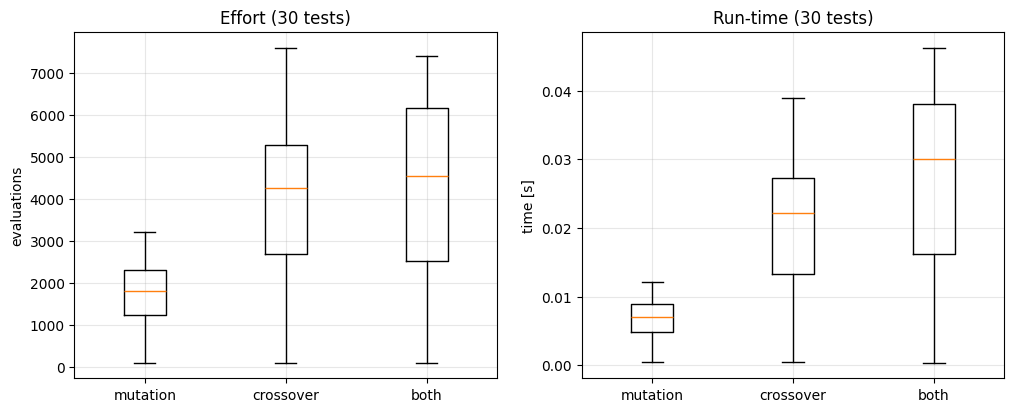

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].boxplot([res[m]["evals"] for m in methods])
ax[0].set_xticks([1, 2, 3], methods); ax[0].set_ylabel("evaluations"); ax[0].set_title("Effort (30 tests)")
ax[0].grid(alpha=0.3)
ax[1].boxplot([res[m]["time"] for m in methods])
ax[1].set_xticks([1, 2, 3], methods); ax[1].set_ylabel("time [s]"); ax[1].set_title("Run-time (30 tests)")
ax[1].grid(alpha=0.3)
plt.show()

## Step 7 – Discussion

- **Length is not given, so the feedback must carry it.** The length penalty in the score pushes the population towards the right length, because wrong lengths lower the score.
- **Mutation** changes the length (insert or delete) and the bits. It is the only way to explore new lengths when the population has converged.
- **Crossover** can combine a good prefix from one parent with a good suffix from another. Because the cut points are independent, it can also create new lengths, but the children can be worse than both parents.
- **Observed result:** Mutation only found the pattern in all 30 tests, while crossover only (33 %) and mutation with crossover (47 %) often stagnated. Crossover mostly found the right length (93 %), but the bits got stuck, because the population lost diversity. Mutation is therefore essential in this variable-length setting.
- **Compare the success rates and the right-length rates.** A method can find many bits right but still get the length wrong, which the success rate alone does not show.
- **Limit of this approach:** The score is only a proxy for closeness. If a guess has the right bits but the wrong length, the score can be low, so the search may need more generations.

**Caveat:** The score rule is our own design, because the exercise leaves the feedback open. The results depend on this choice, the seeds and the stagnation limit.

## Footer

In [8]:
import platform
from datetime import datetime
print("-----------------------------------")
print(platform.system(), "|", platform.release())
print("Datetime:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python Version:", platform.python_version())
print("-----------------------------------")

-----------------------------------
Darwin | 27.2.0
Datetime: 2026-11-11 14:40:35
Python Version: 3.10.20
-----------------------------------
